# Workshop 3 · Parte A · Pasos 1 y 2 — EDA, limpieza y armonización
**Objetivo:** perfilar los 5 CSV de World Happiness (2015–2019), detectar problemas de calidad y esquema, y producir un dataset unificado listo para ML.

Entregables de este notebook: observaciones de calidad, propuesta de esquema unificado y `data/processed/happiness_unified.csv`.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
ROOT = Path("..") if Path("../data").exists() else Path(".")
RAW, PROC = ROOT/"data/raw", ROOT/"data/processed"
raw = {y: pd.read_csv(RAW/f"{y}.csv") for y in range(2015, 2020)}

## 1. Perfilado por archivo
Filas/columnas, tipos, nulos y duplicados.

In [2]:
rows = []
for y, d in raw.items():
    country_col = [c for c in d.columns if "ountry" in c][0]
    rows.append(dict(year=y, rows=d.shape[0], cols=d.shape[1],
                     null_cells=int(d.isna().sum().sum()),
                     duplicated_rows=int(d.duplicated().sum()),
                     duplicated_countries=int(d[country_col].duplicated().sum()),
                     numeric_cols=int(d.select_dtypes("number").shape[1])))
pd.DataFrame(rows).set_index("year")

,rows,cols,null_cells,duplicated_rows,duplicated_countries,numeric_cols
year,,,,,,
2015,158,12,0,0,0,10
2016,157,13,0,0,0,11
2017,155,12,0,0,0,11
2018,156,9,1,0,0,8
2019,156,9,0,0,0,8


In [3]:
# Columnas con nulos
for y, d in raw.items():
    n = d.isna().sum(); n = n[n > 0]
    if len(n): print(y, n.to_dict()); print(d[d.isna().any(axis=1)].iloc[:, :4], "\n")

2018 {'Perceptions of corruption': 1}
    Overall rank     Country or region  Score  GDP per capita
19            20  United Arab Emirates  6.774           2.096 



## 2. Inconsistencias de esquema entre años
Cada año nombra distinto las mismas variables y trae columnas que otros años no tienen.

In [4]:
allcols = sorted(set().union(*[set(d.columns) for d in raw.values()]))
pd.DataFrame({y: [c in d.columns for c in allcols] for y, d in raw.items()}, index=allcols).astype(int)

,2015,2016,2017,2018,2019
Country,1,1,1,0,0
Country or region,0,0,0,1,1
Dystopia Residual,1,1,0,0,0
Dystopia.Residual,0,0,1,0,0
Economy (GDP per Capita),1,1,0,0,0
Economy..GDP.per.Capita.,0,0,1,0,0
Family,1,1,1,0,0
Freedom,1,1,1,0,0
Freedom to make life choices,0,0,0,1,1
GDP per capita,0,0,0,1,1


**Hallazgos de esquema**
- 2015/2016/2017 usan `Country`; 2018/2019 usan `Country or region`.
- Nombres distintos para las mismas variables: `Economy (GDP per Capita)` / `Economy..GDP.per.Capita.` / `GDP per capita`; `Family` / `Social support`; `Health (Life Expectancy)` / `Healthy life expectancy`; `Freedom` / `Freedom to make life choices`; `Trust (Government Corruption)` / `Perceptions of corruption`.
- `Region` solo existe en 2015 y 2016. `Standard Error`, intervalos de confianza y `Whisker.*` solo existen en algunos años.
- `Dystopia Residual` existe en 2015–2017 pero no en 2018–2019.
- 2017 viene con ~15 decimales y encabezados con comillas/puntos (exportado desde R).

In [5]:
# Nombres de país que no aparecen en 2019 (variantes de nombre vs. países que realmente entran/salen)
names = {y: set(d.filter(regex="ountry").iloc[:, 0].str.strip()) for y, d in raw.items()}
for y in range(2015, 2019): print(y, sorted(names[y] - names[2019]))

2015 ['Angola', 'Djibouti', 'Macedonia', 'North Cyprus', 'Oman', 'Somaliland region', 'Sudan', 'Suriname', 'Trinidad and Tobago']
2016 ['Angola', 'Belize', 'Macedonia', 'North Cyprus', 'Puerto Rico', 'Somaliland Region', 'Sudan', 'Suriname', 'Trinidad and Tobago']
2017 ['Angola', 'Belize', 'Hong Kong S.A.R., China', 'Macedonia', 'North Cyprus', 'Sudan', 'Taiwan Province of China', 'Trinidad and Tobago']
2018 ['Angola', 'Belize', 'Macedonia', 'Sudan']


## 3. Armonización a un esquema unificado

In [6]:
RENAME = {
 "Country": "country", "Country or region": "country",
 "Happiness Score": "happiness_score", "Happiness.Score": "happiness_score", "Score": "happiness_score",
 "Economy (GDP per Capita)": "gdp", "Economy..GDP.per.Capita.": "gdp", "GDP per capita": "gdp",
 "Family": "family", "Social support": "family",
 "Health (Life Expectancy)": "health", "Health..Life.Expectancy.": "health", "Healthy life expectancy": "health",
 "Freedom": "freedom", "Freedom to make life choices": "freedom",
 "Generosity": "generosity",
 "Trust (Government Corruption)": "corruption", "Trust..Government.Corruption.": "corruption",
 "Perceptions of corruption": "corruption",
}
COUNTRY_FIX = {
 "Macedonia": "North Macedonia", "North Cyprus": "Northern Cyprus",
 "Somaliland region": "Somaliland Region", "Hong Kong S.A.R., China": "Hong Kong",
 "Taiwan Province of China": "Taiwan", "Trinidad and Tobago": "Trinidad & Tobago",
}
UNIFIED = ["country", "year", "gdp", "family", "health", "freedom", "generosity", "corruption", "happiness_score"]

frames = []
for y, d in raw.items():
    f = d.rename(columns=RENAME)
    f["year"] = y
    f = f[UNIFIED].copy()
    f["country"] = f["country"].str.strip().replace(COUNTRY_FIX)
    for c in UNIFIED[2:]:
        f[c] = pd.to_numeric(f[c], errors="raise").astype("float64")
    f["year"] = f["year"].astype("int64")
    frames.append(f)
unified = pd.concat(frames, ignore_index=True)
print(unified.shape); unified.dtypes

(782, 9)


country                str
year                 int64
gdp                float64
family             float64
health             float64
freedom            float64
generosity         float64
corruption         float64
happiness_score    float64
dtype: object

In [7]:
# Países con menos de 5 años: ¿variantes de nombre sin resolver o entradas/salidas reales de la encuesta?
cnt = unified.groupby("country")["year"].nunique()
cnt[cnt < 5].sort_values()

country
Gambia                      1
Djibouti                    1
Oman                        1
Puerto Rico                 1
Somaliland Region           2
Suriname                    2
Swaziland                   2
Belize                      3
Comoros                     3
Laos                        4
Lesotho                     4
Namibia                     4
Mozambique                  4
Somalia                     4
Angola                      4
Central African Republic    4
Sudan                       4
South Sudan                 4
Name: year, dtype: int64

Los países con menos de 5 años son entradas/salidas reales de la encuesta (Angola, Belize, Sudan, Puerto Rico, Somaliland…), no variantes de nombre. **Decisión:** se conservan; cada fila es una observación país-año válida.

In [8]:
print("Nulos tras unificar:\n", unified.isna().sum()[lambda s: s > 0])
print("Duplicados país-año:", unified.duplicated(["country", "year"]).sum())
unified[unified.isna().any(axis=1)]

Nulos tras unificar:
 corruption    1
dtype: int64
Duplicados país-año: 0


,country,year,gdp,family,health,freedom,generosity,corruption,happiness_score
489,United Arab Emirates,2018,2.096,0.776,0.67,0.284,0.186,NaN,6.774


### Decisión de limpieza: valor faltante de `corruption`
Hay un único nulo (Emiratos Árabes Unidos, 2018). **Se imputa con la media de `corruption` del mismo país en los otros años**, no con la media global: la percepción de corrupción es específica de cada país y estable en el tiempo. Eliminar la fila perdería una observación completa por un solo campo faltante.

In [9]:
mask = unified["corruption"].isna()
fill = unified.groupby("country")["corruption"].transform("mean")
print(unified.loc[mask, ["country", "year"]].assign(imputed=fill[mask]))
unified["corruption"] = unified["corruption"].fillna(fill)
unified["corruption"] = unified["corruption"].fillna(unified["corruption"].median())  # salvaguarda
assert unified.isna().sum().sum() == 0

                  country  year   imputed
489  United Arab Emirates  2018  0.311982


## 4. Posibles outliers
Método IQR (1.5×). **No se eliminan**: los ceros en GDP/health/family son valores reales de la fuente (países con datos muy bajos), y el modelo debe poder verlos en streaming.

Outliers IQR: {'gdp': 0, 'family': 10, 'health': 0, 'freedom': 0, 'generosity': 17, 'corruption': 68, 'happiness_score': 0}
Valores == 0: {'gdp': 5, 'family': 5, 'health': 5, 'freedom': 5, 'generosity': 5, 'corruption': 6, 'happiness_score': 0}


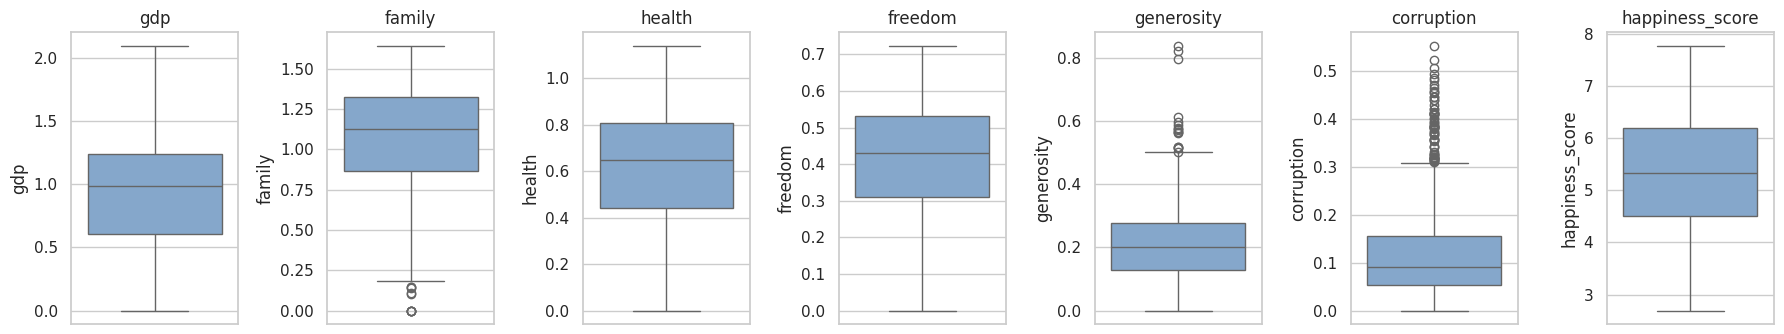

In [10]:
num = ["gdp", "family", "health", "freedom", "generosity", "corruption", "happiness_score"]
out = {}
for c in num:
    q1, q3 = unified[c].quantile([.25, .75]); iqr = q3 - q1
    out[c] = int(((unified[c] < q1 - 1.5*iqr) | (unified[c] > q3 + 1.5*iqr)).sum())
print("Outliers IQR:", out)
print("Valores == 0:", (unified[num] == 0).sum().to_dict())
fig, ax = plt.subplots(1, 7, figsize=(18, 3.5))
for a, c in zip(ax, num): sns.boxplot(y=unified[c], ax=a, color="#7aa6d6"); a.set_title(c)
plt.tight_layout(); plt.show()

In [11]:
unified[(unified.gdp == 0) | (unified.health == 0) | (unified.family == 0)][["country","year","gdp","family","health","happiness_score"]]

,country,year,gdp,family,health,happiness_score
119,Congo (Kinshasa),2015,0.000000,1.001200,0.098060,4.517
122,Sierra Leone,2015,0.330240,0.955710,0.000000,4.507
147,Central African Republic,2015,0.078500,0.000000,0.066990,3.678
233,Somalia,2016,0.000000,0.336130,0.114660,5.440
268,Sierra Leone,2016,0.364850,0.628000,0.000000,4.635
312,Togo,2016,0.281230,0.000000,0.248110,3.303
453,Lesotho,2017,0.521021,1.190095,0.000000,3.808
469,Central African Republic,2017,0.000000,0.000000,0.018773,2.693
567,Somalia,2018,0.000000,0.712000,0.115000,4.982
582,Sierra Leone,2018,0.256000,0.813000,0.000000,4.571


**Decisión:** se mantienen. En el contrato del consumidor se validarán rangos plausibles en lugar de eliminar casos extremos reales.

## 5. Estadísticos descriptivos y relaciones

In [12]:
unified[num].describe().T

,count,mean,std,min,25%,50%,75%,max
gdp,782.0,0.916047,0.407340,0.000,0.606500,0.982205,1.236187,2.096000
family,782.0,1.078392,0.329548,0.000,0.869363,1.124735,1.327250,1.644000
health,782.0,0.612416,0.248309,0.000,0.440183,0.647310,0.808000,1.141000
freedom,782.0,0.411091,0.152880,0.000,0.309768,0.431000,0.531000,0.724000
generosity,782.0,0.218576,0.122321,0.000,0.130000,0.201982,0.278832,0.838075
corruption,782.0,0.125674,0.105959,0.000,0.054250,0.091033,0.156243,0.551910
happiness_score,782.0,5.379018,1.127456,2.693,4.509750,5.322000,6.189500,7.769000


In [13]:
unified.groupby("year")[num].mean().round(3)

,gdp,family,health,freedom,generosity,corruption,happiness_score
year,,,,,,,
2015,0.846,0.991,0.630,0.429,0.237,0.143,5.376
2016,0.954,0.794,0.558,0.371,0.243,0.138,5.382
2017,0.985,1.189,0.551,0.409,0.247,0.123,5.354
2018,0.891,1.213,0.597,0.455,0.181,0.113,5.376
2019,0.905,1.209,0.725,0.393,0.185,0.111,5.407


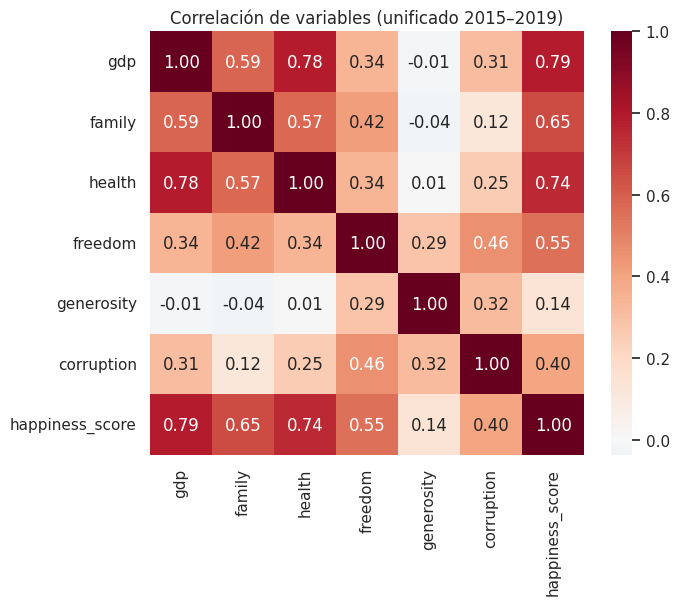

In [14]:
plt.figure(figsize=(7, 5.5))
sns.heatmap(unified[num].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlación de variables (unificado 2015–2019)"); plt.show()

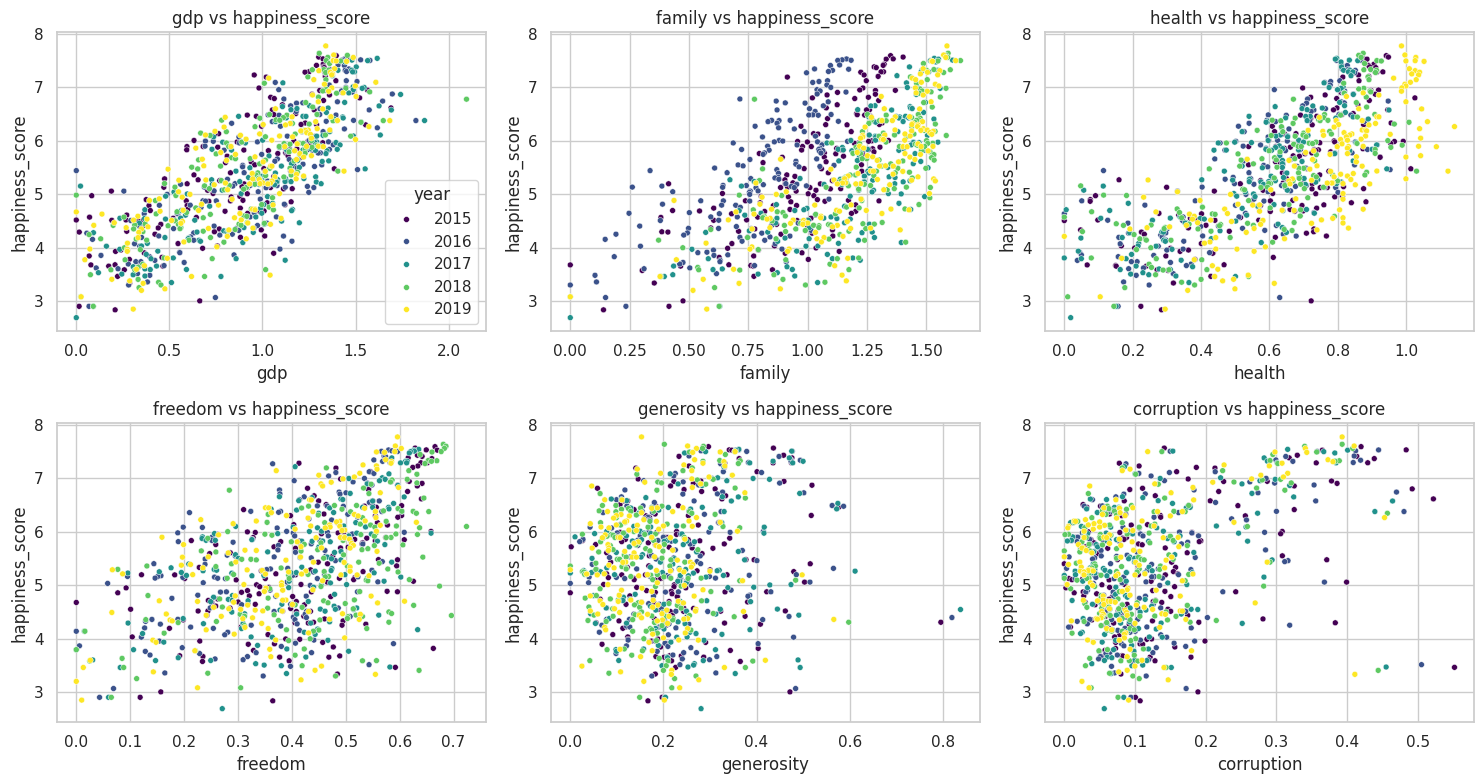

In [15]:
feats = ["gdp", "family", "health", "freedom", "generosity", "corruption"]
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for a, c in zip(ax.ravel(), feats):
    sns.scatterplot(data=unified, x=c, y="happiness_score", hue="year", palette="viridis", s=18, ax=a, legend=(c == "gdp"))
    a.set_title(f"{c} vs happiness_score")
plt.tight_layout(); plt.show()

## 6. Propuesta de esquema unificado y guardado

In [16]:
pd.DataFrame({
  "columna": UNIFIED,
  "tipo": ["string", "int", "float", "float", "float", "float", "float", "float", "float"],
  "descripción": ["País (nombre armonizado)", "Año de la observación", "PIB per cápita (contribución)", "Familia / apoyo social",
                  "Esperanza de vida saludable", "Libertad para tomar decisiones", "Generosidad", "Percepción de corrupción", "Score de felicidad (target)"]})

,columna,tipo,descripción
0,country,string,País (nombre armonizado)
1,year,int,Año de la observación
2,gdp,float,PIB per cápita (contribución)
3,family,float,Familia / apoyo social
4,health,float,Esperanza de vida saludable
5,freedom,float,Libertad para tomar decisiones
6,generosity,float,Generosidad
7,corruption,float,Percepción de corrupción
8,happiness_score,float,Score de felicidad (target)


In [17]:
dropped = ["Region (solo 2015-16)", "Happiness Rank / Overall rank (derivado del target)",
           "Standard Error / CI / Whisker (solo algunos años; derivados del target)",
           "Dystopia Residual (solo 2015-17; score = suma de los 6 factores + residual -> fuga de target)"]
print("Columnas descartadas:\n" + "\n".join("- " + d for d in dropped))
unified = unified.sort_values(["year", "country"]).reset_index(drop=True)
unified.to_csv(PROC/"happiness_unified.csv", index=False)
print(unified.shape, "->", PROC/"happiness_unified.csv")

Columnas descartadas:
- Region (solo 2015-16)
- Happiness Rank / Overall rank (derivado del target)
- Standard Error / CI / Whisker (solo algunos años; derivados del target)
- Dystopia Residual (solo 2015-17; score = suma de los 6 factores + residual -> fuga de target)
(782, 9) -> ../data/processed/happiness_unified.csv
